In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Create output folders
os.makedirs("../outputs/graphs", exist_ok=True)
os.makedirs("../outputs/results", exist_ok=True)

# Load dataset
df = pd.read_csv("../dataset/city_attributes.csv")

# Display data
display(df.head())

print("Shape:", df.shape)
print("Columns:", df.columns.tolist())

,City,Country,Latitude,Longitude
0,Vancouver,Canada,49.249660,-123.119339
1,Portland,United States,45.523449,-122.676208
2,San Francisco,United States,37.774929,-122.419418
3,Seattle,United States,47.606209,-122.332069
4,Los Angeles,United States,34.052231,-118.243683


Shape: (36, 4)
Columns: ['City', 'Country', 'Latitude', 'Longitude']


In [9]:
# Check missing values
print(df.isnull().sum())

# Check duplicates
print("Duplicates:", df.duplicated().sum())

# Remove duplicate records
df = df.drop_duplicates()

# Check data types
print(df.dtypes)

# Check statistical summary
print(df.describe())

City         0
Country      0
Latitude     0
Longitude    0
dtype: int64
Duplicates: 0
City             str
Country          str
Latitude     float64
Longitude    float64
dtype: object
        Latitude   Longitude
count  36.000000   36.000000
mean   37.066743  -73.544668
std     5.815514   51.612349
min    25.774269 -123.119339
25%    32.766126 -105.401312
50%    36.170429  -86.471241
75%    40.998211  -74.874332
max    49.249660   35.216331


In [3]:
print("Shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

display(df.describe(include="all"))

Shape: (36, 4)

Columns:
['City', 'Country', 'Latitude', 'Longitude']

Data Types:
City             str
Country          str
Latitude     float64
Longitude    float64
dtype: object

Missing Values:
City         0
Country      0
Latitude     0
Longitude    0
dtype: int64

Duplicate Records:
0


,City,Country,Latitude,Longitude
count,36,36,36.000000,36.000000
unique,36,3,NaN,NaN
top,Vancouver,United States,NaN,NaN
freq,1,27,NaN,NaN
mean,NaN,NaN,37.066743,-73.544668
std,NaN,NaN,5.815514,51.612349
min,NaN,NaN,25.774269,-123.119339
25%,NaN,NaN,32.766126,-105.401312
50%,NaN,NaN,36.170429,-86.471241
75%,NaN,NaN,40.998211,-74.874332


In [10]:
print("Invalid Latitude:",
      (~df["Latitude"].between(-90, 90)).sum())

print("Invalid Longitude:",
      (~df["Longitude"].between(-180, 180)).sum())

Invalid Latitude: 0
Invalid Longitude: 0


In [11]:
northernmost = df.loc[df["Latitude"].idxmax()]
southernmost = df.loc[df["Latitude"].idxmin()]

print("Northernmost City:")
print(northernmost)

print("\nSouthernmost City:")
print(southernmost)

Northernmost City:
City          Vancouver
Country          Canada
Latitude       49.24966
Longitude   -123.119339
Name: 0, dtype: object

Southernmost City:
City                 Miami
Country      United States
Latitude         25.774269
Longitude       -80.193657
Name: 23, dtype: object


In [12]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

geo = df[["Latitude", "Longitude"]]

scaler = StandardScaler()
geo_scaled = scaler.fit_transform(geo)

kmeans = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

df["Geo_Cluster"] = kmeans.fit_predict(geo_scaled)

print(df[["City", "Country", "Geo_Cluster"]])

                 City        Country  Geo_Cluster
0           Vancouver         Canada            1
1            Portland  United States            1
2       San Francisco  United States            4
3             Seattle  United States            1
4         Los Angeles  United States            4
5           San Diego  United States            4
6           Las Vegas  United States            4
7             Phoenix  United States            4
8         Albuquerque  United States            4
9              Denver  United States            2
10        San Antonio  United States            0
11             Dallas  United States            4
12            Houston  United States            0
13        Kansas City  United States            2
14        Minneapolis  United States            1
15        Saint Louis  United States            2
16            Chicago  United States            2
17          Nashville  United States            4
18       Indianapolis  United States            2


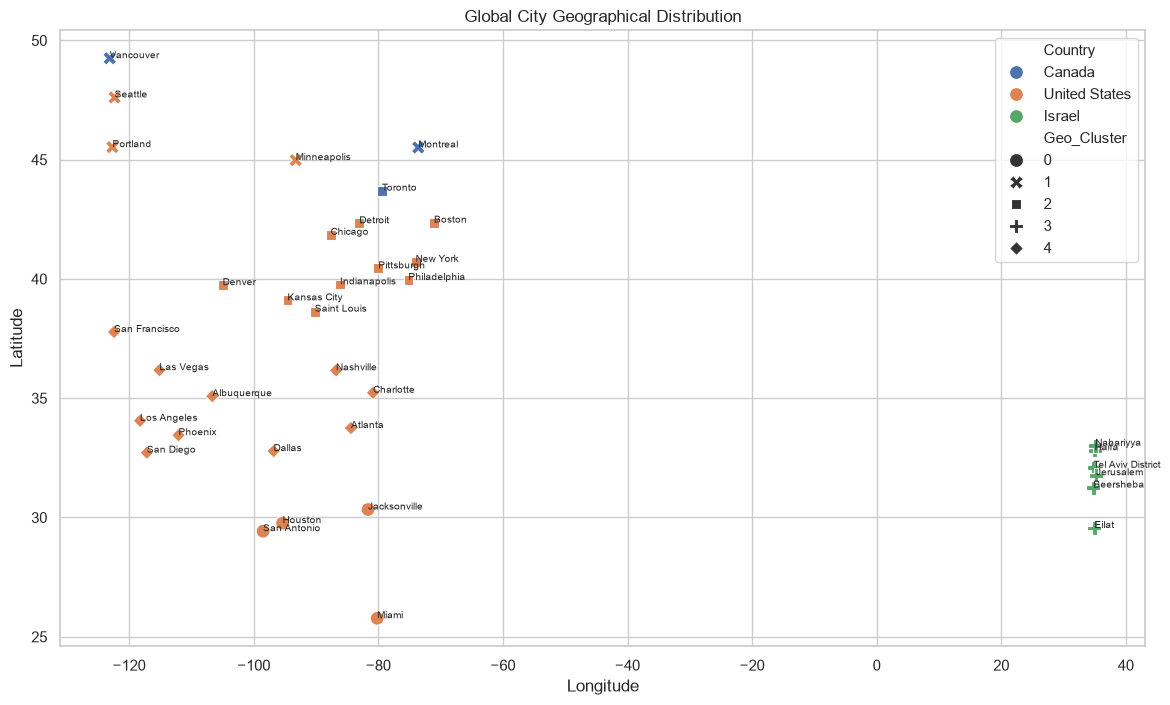

In [13]:
plt.figure(figsize=(14, 8))

sns.scatterplot(
    data=df,
    x="Longitude",
    y="Latitude",
    hue="Country",
    style="Geo_Cluster",
    s=100
)

for _, row in df.iterrows():
    plt.text(
        row["Longitude"],
        row["Latitude"],
        row["City"],
        fontsize=7
    )

plt.title("Global City Geographical Distribution")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.grid(True)

plt.savefig(
    "../outputs/graphs/city_geographical_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Country
United States    27
Israel            6
Canada            3
Name: City, dtype: int64


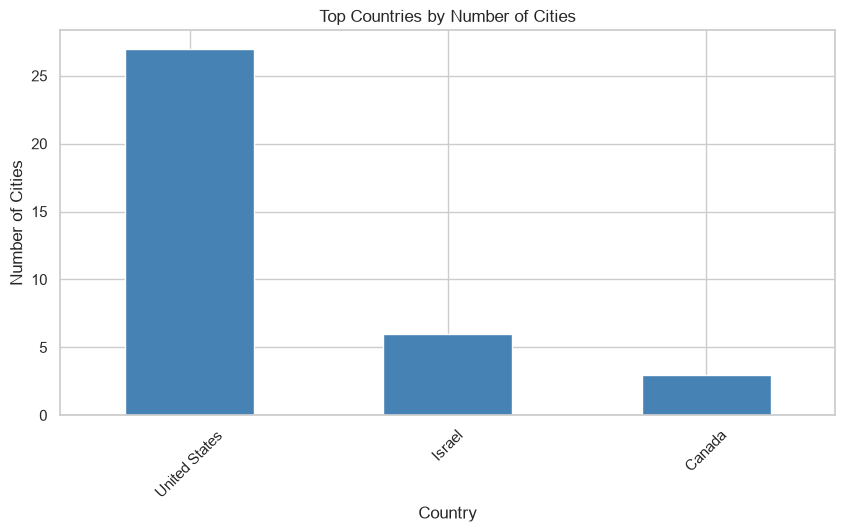

In [14]:
country_count = (
    df.groupby("Country")["City"]
    .nunique()
    .sort_values(ascending=False)
)

print(country_count)

plt.figure(figsize=(10, 5))

country_count.head(10).plot(
    kind="bar",
    color="steelblue"
)

plt.title("Top Countries by Number of Cities")
plt.xlabel("Country")
plt.ylabel("Number of Cities")
plt.xticks(rotation=45)

plt.savefig(
    "../outputs/graphs/top_countries.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

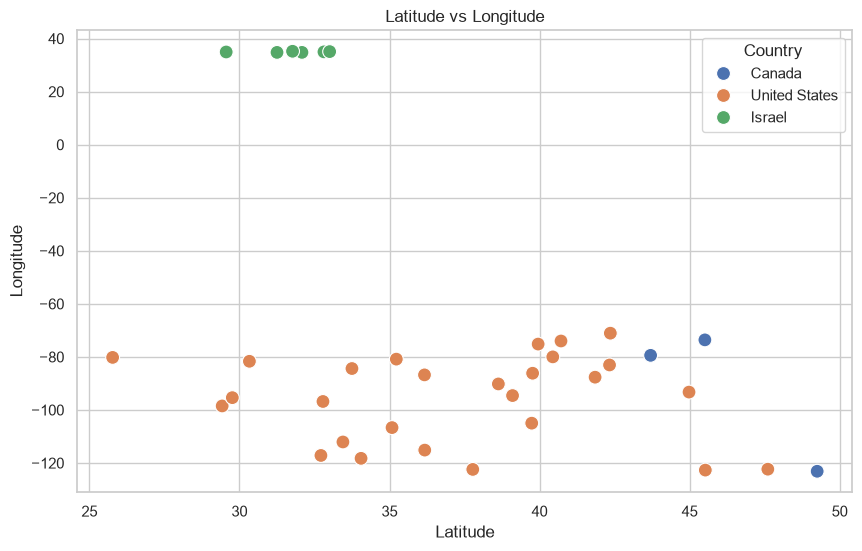

In [15]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Latitude",
    y="Longitude",
    hue="Country",
    s=100
)

plt.title("Latitude vs Longitude")
plt.savefig(
    "../outputs/graphs/latitude_longitude.png",
    dpi=300
)

plt.show()

In [16]:
country_analysis = df.groupby("Country").agg(
    Total_Cities=("City", "nunique"),
    Average_Latitude=("Latitude", "mean"),
    Average_Longitude=("Longitude", "mean")
).reset_index()

print(country_analysis)

         Country  Total_Cities  Average_Latitude  Average_Longitude
0         Canada             3         46.152870         -92.041148
1         Israel             6         31.747274          34.973184
2  United States            27         37.239278         -95.604582


In [17]:
df.to_csv(
    "../outputs/results/cleaned_city_attributes.csv",
    index=False
)

country_analysis.to_csv(
    "../outputs/results/country_analysis.csv",
    index=False
)

print("All files saved successfully!")

All files saved successfully!
